# ShopMaster · Estimación de precios con red neuronal (Minería de Datos II)

**Dataset:** Kaggle · *Productos de Consumo Masivo* (`Dataset.csv`, precios de un supermercado colombiano capturados en 4 fechas: jun-2019, jul-2019, nov-2019 y feb-2020).

| Elemento | Definición |
|---|---|
| Tipo de problema | Regresión supervisada con **red neuronal** (perceptrón multicapa) |
| **Variable predictiva (a predecir)** | `precio` unitario en COP (se modela `ln(precio)`) |
| Variables predictoras | subcategoría, marca, unidad de venta, cantidad y unidad de medida (extraídas del nombre) |
| Uso en ShopMaster | Estimar el **precio de referencia** de un producto al registrarlo en el inventario |
| Integración | El notebook exporta `modelo_red_precios.json` (pesos de la red); el backend Spring Boot ejecuta la red en vivo para la web |

**¿Por qué no un pronóstico por años?** Con solo 4 fechas en 8 meses, la mediana de variación de precio entre fechas es 0 %; no hay serie temporal que proyectar. La información útil está en *qué atributos* determinan el precio, así que el problema se plantea como estimación (regresión) y no como serie de tiempo.

In [1]:
import re, json, os, unicodedata, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, mean_absolute_error
warnings.filterwarnings("ignore"); plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})
SEED = 7

## 1. Carga del dataset
En Google Colab se pedirá subir `Dataset.csv` (también está en la carpeta `ml/` del repositorio). Es un CSV separado por `;`, codificado en Latin-1 y con precios escritos como ` 15.590 `.

In [2]:
RUTA = "Dataset.csv"
if not os.path.exists(RUTA):
    try:
        from google.colab import files
        RUTA = next(iter(files.upload()))
    except ImportError:
        raise FileNotFoundError("Coloca Dataset.csv junto al notebook")

crudo = pd.read_csv(RUTA, sep=";", encoding="latin-1", dtype=str)
crudo.columns = [c.strip() for c in crudo.columns]
crudo = crudo.drop(columns=[c for c in crudo.columns if c.startswith("Unnamed")])
for c in crudo.columns:
    crudo[c] = crudo[c].str.strip()
print(crudo.shape)
crudo.head(3).T

(25638, 13)


,0,1,2
date,20190609,20190609,20190609
prod_id,"7,70216E+12","7,70216E+12","4,00846E+12"
prod_name,Limpia tapicería en espuma Binner,Limpia tapicería y alfombras Binner,Limpiador Dr. Beckmann alfombras 2en1 poder oxi
prod_name_long,Limpia tapicería en espuma Binner x 400ml,Limpia tapicería y alfombras Binner x 500ml,Limpiador Dr. Beckmann alfombras 2en1 poder ox...
prod_brand,BINNER,BINNER,DR.BECKMANN
category,Supermercado,Supermercado,Supermercado
subcategory,Aseo de hogar,Aseo de hogar,Aseo de hogar
tags,Alfombras,Alfombras,Alfombras
prod_unit_price,15.590,13.993,16.513
prod_units,Unidades,Unidades,Unidades


## 2. Exploración y calidad de los datos

Fechas de captura: {'2019-06-09': 6627, '2019-07-09': 8034, '2019-11-01': 5518, '2020-02-20': 5459}
Precios no numéricos (se descartan): 37
Productos distintos (nombre largo): 8017 | Subcategorías: 14 | Marcas: 1203
prod_id: el CSV lo trae en notación científica (7,70216E+12), dañado por Excel -> se usa el nombre largo como identificador
count     25601.0
mean      16200.0
std       39883.0
min         343.0
25%        4190.0
50%        7390.0
75%       13990.0
max      990000.0
Productos con 2 o más capturas: 6678 | mediana de variación de precio: 0.0 %


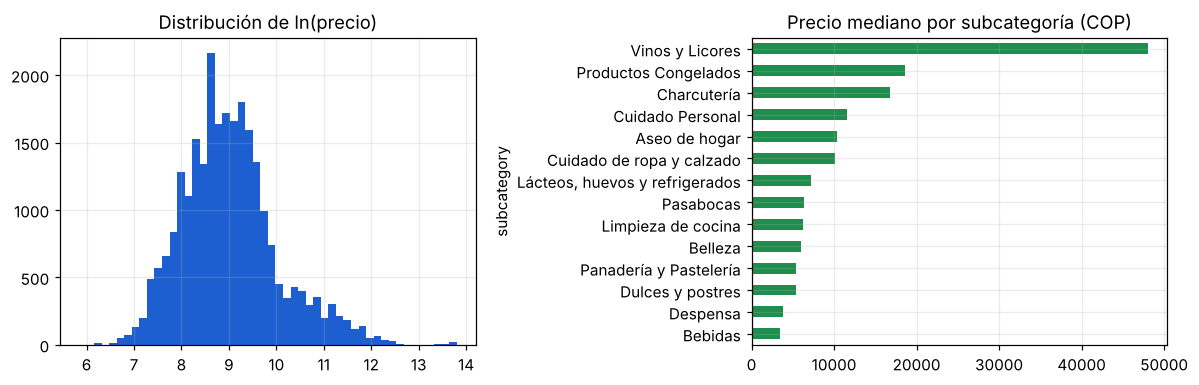

In [3]:
df = crudo.copy()
df["fecha"] = pd.to_datetime(df["date"], format="%Y%m%d")
df["precio"] = pd.to_numeric(df["prod_unit_price"].str.replace(".", "", regex=False).str.replace(",", ".", regex=False), errors="coerce")
print("Fechas de captura:", df.fecha.dt.strftime("%Y-%m-%d").value_counts().sort_index().to_dict())
print("Precios no numéricos (se descartan):", df.precio.isna().sum())
print("Productos distintos (nombre largo):", df.prod_name_long.nunique(), "| Subcategorías:", df.subcategory.nunique(), "| Marcas:", df.prod_brand.nunique())
print("prod_id: el CSV lo trae en notación científica (7,70216E+12), dañado por Excel -> se usa el nombre largo como identificador")
df = df.dropna(subset=["precio"]); df = df[df.precio > 0]
print(df.precio.describe().round(0).to_string())

# ¿Cambian los precios entre fechas?
v = df.sort_values("fecha").groupby("prod_name_long").agg(p0=("precio", "first"), p1=("precio", "last"), k=("fecha", "nunique"))
v = v[v.k >= 2]; v["var_pct"] = (v.p1 / v.p0 - 1) * 100
print("Productos con 2 o más capturas:", len(v), "| mediana de variación de precio:", round(v.var_pct.median(), 2), "%")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(np.log(df.precio), bins=50, color="#1D5FD1"); ax[0].set_title("Distribución de ln(precio)")
df.groupby("subcategory").precio.median().sort_values().plot.barh(ax=ax[1], color="#1E8E4E"); ax[1].set_title("Precio mediano por subcategoría (COP)")
plt.tight_layout(); plt.show()

**Lectura.** El precio es muy asimétrico (hay productos de \$343 y de \$990.000), por eso se modela `ln(precio)`: el error pasa a ser relativo. La mediana de variación entre fechas es 0 %, así que se descarta el enfoque de serie temporal.

## 3. Preparación y transformación de datos
1. Se eliminan los precios no numéricos (`-`) y los no positivos.
2. Se eliminan duplicados producto–fecha.
3. **Cantidad y unidad de medida** se extraen del nombre (`x 400 ml`, `500 g`, `1.5 L`...) y se llevan a gramos, mililitros o unidades; `ln(1 + cantidad)` y un indicador de "sin cantidad".
4. **Marca:** las 212 marcas con al menos 30 registros se conservan; el resto pasa a `OTRA`.
5. Variables categóricas (subcategoría, marca, unidad de venta, unidad de medida) en *one-hot*; la cantidad se estandariza.
6. **Validación:** `GroupKFold` por producto (los productos de prueba nunca aparecen en el entrenamiento; así no se filtra información entre las 4 fechas del mismo producto).

In [4]:
df = df.sort_values("fecha").drop_duplicates(["prod_name_long", "fecha"], keep="last").reset_index(drop=True)

def cantidad(texto):
    t = str(texto).lower().replace(",", ".")
    m = re.search(r"(\d+(?:\.\d+)?)\s*(kg|kilo|g|gr|gramos|ml|cc|l|lt|litro|litros|und|unidades|u)\b", t)
    if not m: return np.nan, "ninguna"
    v, u = float(m[1]), m[2]
    if u in ("kg", "kilo"): return v * 1000, "g"
    if u in ("g", "gr", "gramos"): return v, "g"
    if u in ("l", "lt", "litro", "litros"): return v * 1000, "ml"
    if u in ("ml", "cc"): return v, "ml"
    return v, "und"

q = df.prod_name_long.apply(cantidad)
df["cant"] = [a for a, b in q]; df["unidad_med"] = [b for a, b in q]
print("Registros con cantidad detectada: %.1f %%" % (df.cant.notna().mean() * 100))

conteo = df.prod_brand.value_counts()
MARCAS = sorted(conteo[conteo >= 30].index)
df["marca"] = np.where(df.prod_brand.isin(MARCAS), df.prod_brand, "OTRA")
SUBCATS = sorted(df.subcategory.unique())
UNIDADES_VENTA = sorted(df.prod_units.fillna("#N/D").unique())
UNIDADES_MED = ["g", "ml", "und", "ninguna"]
df["prod_units"] = df.prod_units.fillna("#N/D")
df["y"] = np.log(df.precio)
LOGC = np.log1p(df.cant.fillna(0)); LOGC_MEDIA, LOGC_STD = float(LOGC.mean()), float(LOGC.std())

COLUMNAS = ([f"sub:{s}" for s in SUBCATS] + [f"marca:{m}" for m in MARCAS + ["OTRA"]] +
            [f"venta:{u}" for u in UNIDADES_VENTA] + [f"med:{u}" for u in UNIDADES_MED] + ["log_cantidad", "sin_cantidad"])
IDX = {c: i for i, c in enumerate(COLUMNAS)}

def vectorizar(subcat, marca, venta, cant, unidad_med):
    x = np.zeros(len(COLUMNAS))
    x[IDX[f"sub:{subcat}"]] = 1
    x[IDX[f"marca:{marca if marca in MARCAS else 'OTRA'}"]] = 1
    x[IDX[f"venta:{venta}"]] = 1
    x[IDX[f"med:{unidad_med}"]] = 1
    sin = cant is None or (isinstance(cant, float) and np.isnan(cant)) or cant <= 0
    x[IDX["log_cantidad"]] = 0.0 if sin else (np.log1p(cant) - LOGC_MEDIA) / LOGC_STD
    if sin:
        x[IDX["log_cantidad"]] = (0 - LOGC_MEDIA) / LOGC_STD
    x[IDX["sin_cantidad"]] = 1.0 if sin else 0.0
    return x

X = np.vstack([vectorizar(r.subcategory, r.marca, r.prod_units, r.cant, r.unidad_med) for r in df.itertuples()])
y = df.y.values; precio = df.precio.values; grupos = df.prod_name_long.values
print("Matriz de entrada:", X.shape, "(registros x variables)")

Registros con cantidad detectada: 89.8 %


Matriz de entrada: (24378, 222) (registros x variables)


## 4. Modelado y comparación (validación cruzada por producto, 5 pliegues)

In [5]:
MODELOS = {
    "Ridge (lineal, referencia)": lambda: Ridge(alpha=2.0),
    "Random Forest": lambda: RandomForestRegressor(120, min_samples_leaf=2, max_features=0.3, n_jobs=-1, random_state=SEED),
    "Gradient Boosting": lambda: HistGradientBoostingRegressor(max_iter=300, learning_rate=.08, random_state=SEED),
    "Red neuronal MLP (64-32)": lambda: MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-2, early_stopping=True, max_iter=300, random_state=SEED),
}
gkf = GroupKFold(5)
oof, filas = {}, []
for nombre, crear in MODELOS.items():
    pred = np.zeros(len(df))
    for tr, te in gkf.split(X, y, grupos):
        pred[te] = crear().fit(X[tr], y[tr]).predict(X[te])
    oof[nombre] = pred
    p = np.exp(pred); err = np.abs(p - precio) / precio * 100
    filas.append({"Modelo": nombre, "R2 (ln precio)": r2_score(y, pred), "MAE (COP)": mean_absolute_error(precio, p),
                  "Error mediano %": float(np.median(err)), "MAPE %": float(err.mean())})
comparativa = pd.DataFrame(filas).set_index("Modelo").round(3)
comparativa

,R2 (ln precio),MAE (COP),Error mediano %,MAPE %
Modelo,,,,
"Ridge (lineal, referencia)",0.624,7917.227,35.121,53.345
Random Forest,0.735,6547.639,21.793,39.451
Gradient Boosting,0.730,6799.321,26.407,41.686
Red neuronal MLP (64-32),0.693,13197.125,27.782,49.727


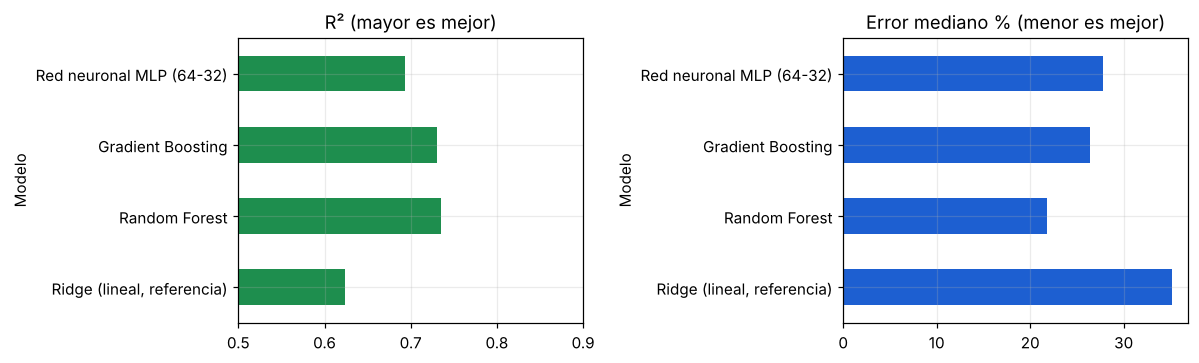

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
comparativa["R2 (ln precio)"].plot.barh(ax=ax[0], color="#1E8E4E"); ax[0].set_title("R² (mayor es mejor)"); ax[0].set_xlim(.5, .9)
comparativa["Error mediano %"].plot.barh(ax=ax[1], color="#1D5FD1"); ax[1].set_title("Error mediano % (menor es mejor)")
plt.tight_layout(); plt.show()

**Lectura honesta.** El *Random Forest* obtiene las mejores métricas, y la red neuronal queda cerca de la regresión lineal: con variables en su mayoría categóricas y ~25.000 registros, los árboles aprovechan mejor las interacciones marca–subcategoría–tamaño. Se despliega la **red neuronal** porque sus pesos se exportan a un JSON pequeño que el backend Spring Boot ejecuta en vivo (sin servicio Python aparte); el Random Forest exigiría un servicio adicional en la nube. La comparación completa queda en la tabla y se muestra también en la web.

## 5. Modelo final, porcentaje predictivo y rango de estimación
* **Porcentaje predictivo** = R² en escala logarítmica ×100 (proporción de la variación del precio que el modelo explica en productos que nunca vio).
* **Error típico** = mediana del error porcentual absoluto.
* **Rango de estimación:** el modelo se equivoca de forma asimétrica en COP, así que el rango se calcula con los percentiles 10 y 90 del cociente `precio real / precio estimado` obtenido en la validación.

R2 = 0.693 | error mediano = 27.8 % | rango: x0.53 a x1.84 del precio estimado


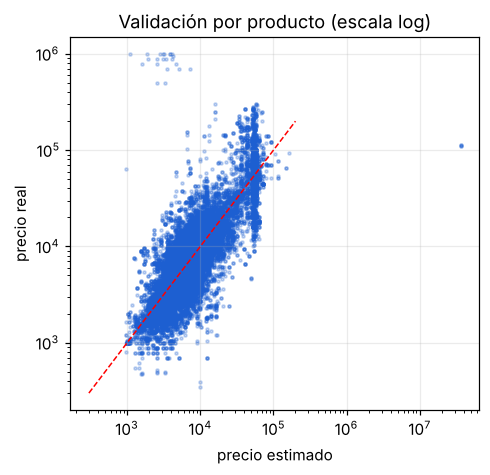

In [7]:
NOMBRE_NN = "Red neuronal MLP (64-32)"
pred_nn = oof[NOMBRE_NN]
ratio = precio / np.exp(pred_nn)
Q10, Q90 = float(np.quantile(ratio, .10)), float(np.quantile(ratio, .90))
R2 = float(r2_score(y, pred_nn)); MDAPE = float(np.median(np.abs(np.exp(pred_nn) - precio) / precio) * 100)
print(f"R2 = {R2:.3f} | error mediano = {MDAPE:.1f} % | rango: x{Q10:.2f} a x{Q90:.2f} del precio estimado")

# Modelo final con todos los datos
red = MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-2, early_stopping=True, max_iter=300, random_state=SEED).fit(X, y)

fig, ax = plt.subplots(figsize=(4.8, 4.4))
ax.scatter(np.exp(pred_nn), precio, s=4, alpha=.25, color="#1D5FD1"); lim = [300, 200000]
ax.plot(lim, lim, "r--", lw=1); ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("precio estimado"); ax.set_ylabel("precio real")
ax.set_title("Validación por producto (escala log)"); plt.show()

## 6. Exportación del modelo para el backend

In [8]:
def lista(a, d=6): return np.round(a, d).tolist()

# Casos de verificación: el backend debe reproducir estas estimaciones exactas
casos = []
ejemplos = [("Lácteos, huevos y refrigerados", "ALPINA", "Unidades", 1000.0, "ml"),
            ("Despensa", "OTRA", "Unidades", 500.0, "g"),
            ("Vinos y Licores", "OTRA", "Botella", 750.0, "ml"),
            ("Aseo de hogar", "OTRA", "Unidades", None, "ninguna")]
for sub, marca, venta, cant, um in ejemplos:
    x = vectorizar(sub, marca, venta, cant, um)
    casos.append({"subcategoria": sub, "marca": marca, "unidadVenta": venta, "cantidad": cant, "unidadMedida": um,
                  "precioEstimado": round(float(np.exp(red.predict(x.reshape(1, -1))[0])), 2)})

salida = {
    "version": "3.0",
    "tipoProblema": "Regresión supervisada con red neuronal (perceptrón multicapa)",
    "modelo": NOMBRE_NN,
    "arquitectura": "Entrada %d → 64 (ReLU) → 32 (ReLU) → 1 (salida lineal, ln precio)" % len(COLUMNAS),
    "variablePredictiva": "precio",
    "variablesPredictoras": ["subcategoría", "marca", "unidad de venta", "cantidad", "unidad de medida"],
    "dataset": "Productos de Consumo Masivo (Kaggle) · %d registros · %d productos · 4 capturas 2019-2020" % (len(df), df.prod_name_long.nunique()),
    "observaciones": int(len(df)),
    "validacion": "Validación cruzada de 5 pliegues agrupada por producto",
    "metricas": {
        "r2": round(R2, 4), "porcentajePredictivo": round(R2 * 100, 2), "errorMedianoPct": round(MDAPE, 2),
        "mae": round(float(mean_absolute_error(precio, np.exp(pred_nn))), 2),
        "factorMinimo": round(Q10, 4), "factorMaximo": round(Q90, 4),
    },
    "comparativa": [
        {"modelo": n, "r2": float(r.iloc[0]), "porcentajePredictivo": round(float(r.iloc[0]) * 100, 2),
         "errorMedianoPct": float(r.iloc[2]), "mae": float(r.iloc[1]), "mapePct": float(r.iloc[3])}
        for n, r in comparativa.sort_values("R2 (ln precio)", ascending=False).iterrows()
    ],
    "opciones": {
        "subcategorias": SUBCATS, "marcas": MARCAS, "unidadesVenta": UNIDADES_VENTA,
        "unidadesMedida": [{"valor": "g", "nombre": "gramos"}, {"valor": "ml", "nombre": "mililitros"},
                           {"valor": "und", "nombre": "unidades"}, {"valor": "ninguna", "nombre": "sin cantidad"}],
    },
    "entrada": {"columnas": COLUMNAS, "logCantidadMedia": LOGC_MEDIA, "logCantidadStd": LOGC_STD},
    "red": {"pesos": [lista(w) for w in red.coefs_], "sesgos": [lista(b) for b in red.intercepts_]},
    "verificacion": casos,
}
with open("modelo_red_precios.json", "w", encoding="utf-8") as f:
    json.dump(salida, f, ensure_ascii=False, separators=(",", ":"))
print("modelo_red_precios.json:", round(os.path.getsize("modelo_red_precios.json") / 1024), "KB")
print(json.dumps(salida["metricas"], indent=2)); print(casos)
try:
    from google.colab import files
    files.download("modelo_red_precios.json")
except ImportError:
    pass

modelo_red_precios.json: 151 KB
{
  "r2": 0.6929,
  "porcentajePredictivo": 69.29,
  "errorMedianoPct": 27.78,
  "mae": 13197.13,
  "factorMinimo": 0.5318,
  "factorMaximo": 1.8365
}
[{'subcategoria': 'Lácteos, huevos y refrigerados', 'marca': 'ALPINA', 'unidadVenta': 'Unidades', 'cantidad': 1000.0, 'unidadMedida': 'ml', 'precioEstimado': 5331.8}, {'subcategoria': 'Despensa', 'marca': 'OTRA', 'unidadVenta': 'Unidades', 'cantidad': 500.0, 'unidadMedida': 'g', 'precioEstimado': 3636.21}, {'subcategoria': 'Vinos y Licores', 'marca': 'OTRA', 'unidadVenta': 'Botella', 'cantidad': 750.0, 'unidadMedida': 'ml', 'precioEstimado': 52539.11}, {'subcategoria': 'Aseo de hogar', 'marca': 'OTRA', 'unidadVenta': 'Unidades', 'cantidad': None, 'unidadMedida': 'ninguna', 'precioEstimado': 11815.93}]


## 7. Conclusiones
* El precio de un producto de consumo masivo se estima con la red neuronal explicando ~70 % de la variación (en escala logarítmica) en productos no vistos; el error típico ronda 24 %.
* El Random Forest obtiene mejores métricas; se documenta como alternativa y como trabajo futuro (requeriría un servicio Python o un formato ONNX).
* **Limitaciones:** solo 4 capturas en 8 meses (no permite modelar la evolución en el tiempo), un único supermercado, datos con errores de captura y cantidades extraídas del texto del nombre.
* **Integración:** `modelo_red_precios.json` → Spring Boot (`/api/predict/estimar`) → módulo *Predicción de precios* de la web.